In [1]:
import re, json, random
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from pypdf import PdfReader
from wordcloud import WordCloud, STOPWORDS

LEGAL_STOP = {
    "any", "act", "person", "persons", "shall", "may", "article", "articles",
    "clause", "clauses", "section", "sections", "thereof", "hereof", "herein",
    "thereto", "therein", "whether", "provision", "provisions", "also", "one",
    "two", "three", "new", "case", "cases", "such", "subs", "ins", "ibid",
    "vide", "ss", "sub", "amendment", "inserted", "substituted", "omitted",
    "ceased", "operate", "constitution", "india", "indian", "part", "schedule",
    "words", "word", "date", "per", "ors", "etc", "without", "within", "made",
    "make", "makes", "given", "under", "respect", "purposes", "purpose",
}
STOP = set(STOPWORDS) | LEGAL_STOP

def tokens(text):
    return [w for w in re.findall(r"[a-z]{3,}", text.lower()) if w not in STOP]

raw = "\n".join((p.extract_text() or "") for p in PdfReader("constitution.pdf").pages)
freq = Counter(tokens(raw))
print(freq.most_common(25))

[('state', 1482), ('law', 644), ('president', 559), ('court', 533), ('parliament', 501), ('union', 499), ('council', 468), ('house', 396), ('states', 384), ('legislature', 363), ('governor', 333), ('paragraph', 327), ('legislative', 314), ('office', 307), ('government', 299), ('district', 287), ('provided', 271), ('territory', 252), ('order', 251), ('members', 251), ('land', 242), ('assembly', 241), ('specified', 240), ('scheduled', 235), ('commission', 229)]


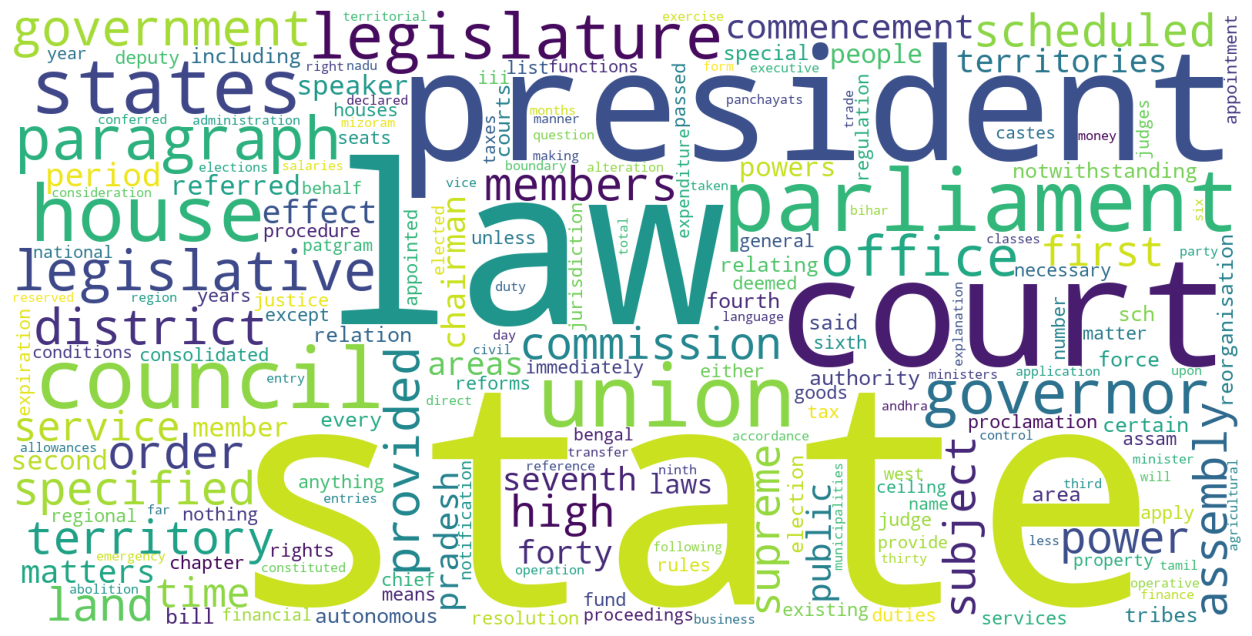

In [2]:
wc = WordCloud(width=1600, height=800, background_color="white",
               max_words=200, colormap="viridis").generate_from_frequencies(freq)
plt.figure(figsize=(16, 8))
plt.imshow(wc)
plt.axis("off")
plt.savefig("wordcloud.png", dpi=200, bbox_inches="tight")
plt.show()

In [3]:
top = dict(freq.most_common(100))
lo, hi = min(top.values()), max(top.values())
tags = []
for w in sorted(top):
    size = 14 + (top[w] - lo) / max(hi - lo, 1) * 56
    color = f"hsl({random.randint(0, 360)},65%,40%)"
    tags.append(f'<a style="font-size:{size:.0f}px;color:{color};margin:6px;'
                f'display:inline-block;text-decoration:none" '
                f'title="{top[w]} occurrences">{w}</a>')

with open("tagcloud.html", "w", encoding="utf-8") as f:
    f.write(f'<html><body style="font-family:Georgia;text-align:center;padding:30px">'
            f'<h2>Tag Cloud: Constitution of India</h2>{"".join(tags)}</body></html>')
print("saved tagcloud.html")

saved tagcloud.html


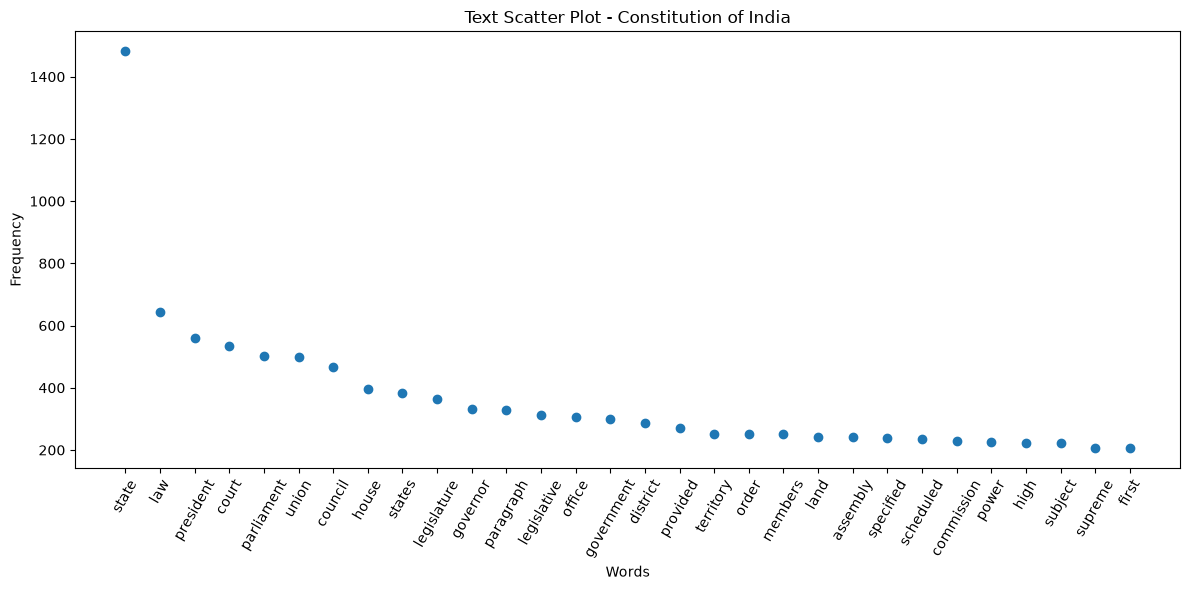

In [6]:

# 3. Text Scatter Plot
top_words = freq.most_common(30)
plt.figure(figsize=(12, 6))
plt.scatter(range(len(top_words)), [n for w, n in top_words])
plt.xticks(range(len(top_words)),
           [w for w, n in top_words], rotation=60)
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Text Scatter Plot - Constitution of India")
plt.tight_layout()
plt.show()


In [8]:
ROOT = "state"   # try "rights", "law", "parliament"

flat = re.sub(r"\s+", " ", raw)
sents = [s.strip() for s in re.split(r"(?<=[.;:])\s", flat)]
sents = [re.sub(r"[^A-Za-z ,'-]", "", s).lower() for s in sents
         if ROOT in s.lower() and 5 < len(s.split()) < 30]
rows = [["Phrases"]] + [[s] for s in sents[:400]]

with open("wordtree.html", "w", encoding="utf-8") as f:
    f.write(f"""<html><head>
<script src="https://www.gstatic.com/charts/loader.js"></script>
<script>
google.charts.load('current', {{packages:['wordtree']}});
google.charts.setOnLoadCallback(() => {{
  const data = google.visualization.arrayToDataTable({json.dumps(rows)});
  new google.visualization.WordTree(document.getElementById('t')).draw(data,
    {{wordtree: {{format:'implicit', word:'{ROOT}', type:'double'}}}});
}});
</script></head>
<body><div id="t" style="width:100%;height:900px"></div></body></html>""")
print("saved wordtree8.html")

saved wordtree8.html
